# Agents, Session 5: Introduction to Multi-Agent Systems (MAS)

## One agent, too many jobs

DilSeTrips has had a busy month. The concierge now has 12 tools, a system prompt over 3,000 words long, and a reactive safety layer in front. Then this arrives:

> "We're getting married in February! Plan our honeymoon in Bali: what visas we need from India, whether we need travel insurance, a budget under Rs 2 lakh for both of us, and a 6-day itinerary that works for a vegetarian."

The answer is fluent and covers everything, a little. Visa rules get one line, insurance gets a vague "consider it", and the budget never adds up. Prasad recognises the problem from his own startup: he cannot be the developer, the accountant and the lawyer at once, and neither can one agent.

So DilSeTrips is about to become a **team**: several agents, each with its own focus, working together. That is a **multi-agent system (MAS)**, the subject of this session and the next.

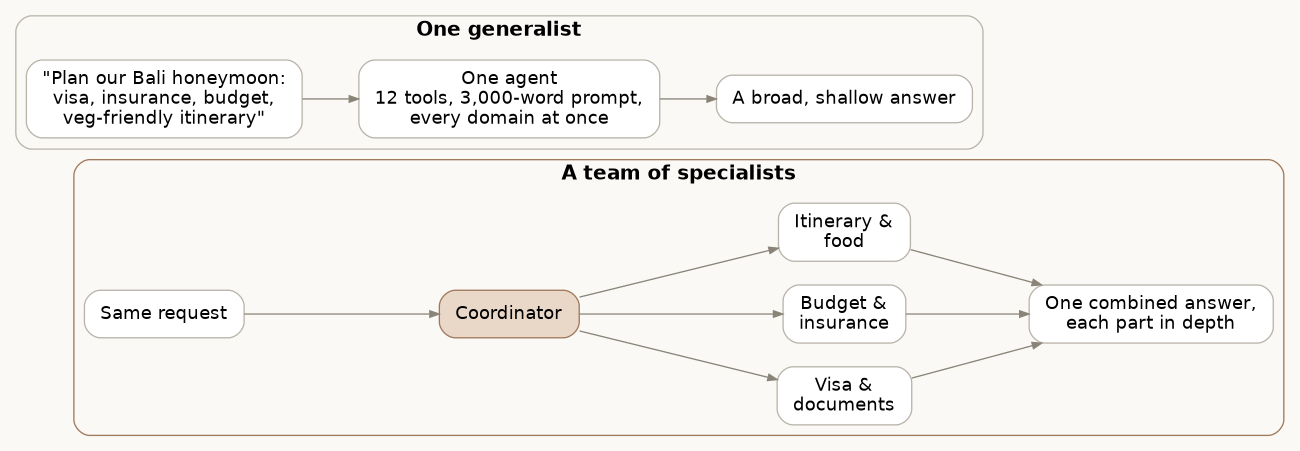

*The same request, handled by one agent doing everything, or by a coordinator and three specialists.*

Two questions run through every design in this session: **who decides, and who talks to whom?** Architectures (centralized, decentralized, hybrid) answer the first. Design patterns (manager/worker, peer/swarm, federated teams, pipeline) answer the second. And because every extra agent means extra messages and extra model calls, each demo prints how many calls it used. A team is never free.

This session is mainly conceptual; the next one builds multi-agent systems properly with LangChain and introduces a framework built for them, CrewAI. The code here is deliberately small: plain Gemini calls, so you can see the *shape* of each design without any framework in the way.

### Setup

About 30 Gemini calls in total. The rate limiter makes calls wait their turn on the free tier.

In [ ]:
%pip install -q "langchain>=1.0" "langchain-google-genai>=4.0" requests

In [ ]:
import os
import json
import requests
from getpass import getpass
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.rate_limiters import InMemoryRateLimiter
from langchain_core.messages import HumanMessage, SystemMessage

if "GOOGLE_API_KEY" not in os.environ:
    os.environ["GOOGLE_API_KEY"] = getpass("Paste your Gemini API key: ")

# At most 4 calls a minute (the free tier allows 5), shared by every agent in this notebook
rate_limiter = InMemoryRateLimiter(requests_per_second=4 / 60, check_every_n_seconds=0.5, max_bucket_size=1)
llm = ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite", google_api_key=os.environ["GOOGLE_API_KEY"], rate_limiter=rate_limiter)

# Every agent in this notebook calls the model through these two helpers, so we can count the cost of each design.
call_count = {"total": 0}
demo_costs = {}

def ask(instructions, request):
    """One agent turn: a system prompt (the agent's role) and a request. Returns text."""
    call_count["total"] = call_count["total"] + 1
    return llm.invoke([SystemMessage(content=instructions), HumanMessage(content=request)]).text

def ask_structured(schema, instructions, request):
    """One agent turn that must return data in the shape of `schema`."""
    call_count["total"] = call_count["total"] + 1
    return llm.with_structured_output(schema).invoke([SystemMessage(content=instructions), HumanMessage(content=request)])

print(ask("You are a friendly teacher.", "In one sentence, welcome a class to a session on multi-agent systems."))

## 1. Why one agent is not always enough

Start with a simple picture. A single cleaning robot works inside a huge airport: thousands of people, spills appearing everywhere, gates opening and closing. It does its job, but it cannot keep up. Now deploy 50 robots: each cleans a zone, they tell each other where spills are, and they coordinate so they do not collide. In a big, busy, changing place, many robots working together beat one.

The same is true for LLM systems. A single chatbot trained to answer everything, from medical advice to legal questions to travel bookings, gives incomplete or wrong answers in complex domains because it must do everything alone. A **team of LLM agents**, one for healthcare, one for finance, one for travel, with a coordinator passing each question to the right expert, can handle a multi-step task like planning a medical trip abroad with insurance, doctor appointments and tickets.

### What a single agent is, and where it breaks

From Session 2, a single agent has four parts: **perception** (how it receives input), **memory** (what it keeps from past interactions), **planning** (how it decides the next steps) and **tools or actions** (what it can do to the world). An assistant that perceives your message, remembers earlier turns, plans a reply and uses a calculator or search tool is a single agent. That works when the problem is **simple and contained**, such as one assistant managing your to-do list.

But a single agent runs into four limits:

- **Knowledge overload:** one agent trying to master medicine, finance and travel becomes shallow or error-prone.
- **A performance bottleneck:** one reasoning cycle slows down as tasks multiply.
- **No specialisation:** it cannot be tuned for each domain.
- **Failure fragility:** if that one agent breaks or makes a wrong decision, everything fails.

Let us see the first limit on DilSeTrips' honeymoon request. We ask once as a generalist, then ask a **visa specialist** about one part only.

**Before you run it:** how much will each answer say about visas?

In [ ]:
honeymoon_request = ("We're an Indian couple getting married in February. Plan our honeymoon in Bali: what visas we need, "
                     "whether we need travel insurance, a budget under Rs 2 lakh for both of us, and a 6-day vegetarian-friendly itinerary.")
start = call_count["total"]

generalist = ask("You are DilSeTrips, a travel concierge that handles every kind of request. Answer in under 250 words.",
                 honeymoon_request)
visa_specialist = ask("You are a visa and travel-documents specialist for Indian travellers. You only handle visas and documents. "
                      "Answer in under 150 words, and say what the couple should verify on official sites.",
                      honeymoon_request)

print("=== Generalist (whole request) ===\n" + generalist + "\n")
print("=== Visa specialist (one part) ===\n" + visa_specialist)
demo_costs["1. Generalist vs one specialist"] = call_count["total"] - start

The generalist spreads 250 words across four topics, so visas get a sentence or two. The specialist spends its whole answer on visas and documents: which visa, how to apply, what to carry, what to double-check officially. Imagine three more specialists for insurance, budget and itinerary, and you have the idea of a multi-agent system.

Be precise about where the gain comes from. Both "agents" are **the same Gemini model**. The specialist is not smarter; it has a narrower role, a focused prompt and all of its answer budget on one problem. In real systems specialists also get **different tools and data** (a visa rules database, an insurance quote API), and that is where specialisation pays off most. And neither answer here has been checked against an official source: specialisation improves focus, not truth.

### What a multi-agent system is

Picture a busy city: thousands of cars, traffic lights at every junction, delivery trucks, ambulances rushing to hospitals. If *one central brain* had to decide every light, every ambulance route and every delivery, it would be overwhelmed. The city works because **many autonomous entities work together**: each driver decides from the traffic around them, each light responds to its own junction, navigation apps guide vehicles with local information. None has the full picture, yet together they form a working transport system.

> A **multi-agent system** is a system of multiple interacting intelligent agents that **collaborate or compete** to achieve individual or collective goals. Each agent has its own knowledge, capabilities and decision-making, and the behaviour of the whole system **emerges** from their interactions. MAS are used for problems that are difficult or impossible for one agent to handle efficiently.

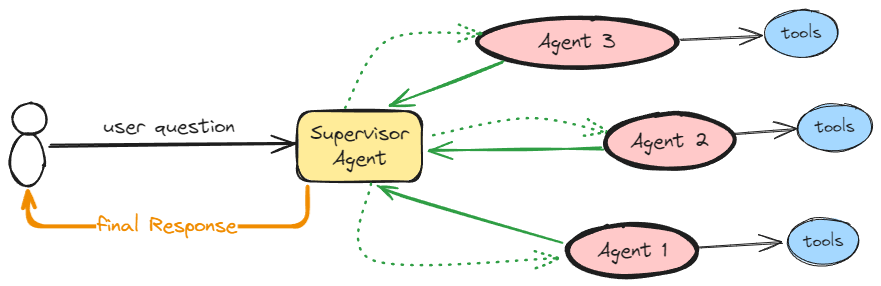

*A common LLM multi-agent shape: a supervisor agent receives the user's question, delegates to agents that each have their own tools, and returns the final response.*

### Three reasons to use more than one agent

Think of organising a music festival. One person booking artists, running the lights, selling tickets, managing security and food stalls would collapse. Specialised teams for artists, security and logistics make it possible. That is the essence of a MAS: **distribute the responsibility**. Three properties of a problem make it necessary.

**a. Complexity and scale.** Some problems are too big for one agent: it would need enormous compute, memory and foresight, and would become slow and error-prone. Global supply chains move millions of products daily through ports, warehouses, factories and shops. One "super-agent" tracking every ship, delay, weather report and customs rule would be overwhelmed. Instead, one agent monitors a port, another optimises truck routes, another forecasts weather disruption, and a coordinator integrates their views.

**b. Distribution.** Information and decisions are spread across places, devices or organisations. Some data is private (hospital records), some is scattered (sensors across a city), some changes too fast to centralise. In a smart power grid, electricity is generated at thousands of solar farms, wind turbines and plants, and consumed in millions of homes and offices; no control room sees it all in real time. Local agents monitor their own node, talk to neighbours, and together balance load and prevent outages.

**c. Dynamics.** Environments change constantly and unpredictably. A single agent with a rigid model fails when things shift; local agents adapt in real time. In city traffic, an accident jams one junction, roadworks slow another, a festival floods a district with pedestrians. A central agent might finish updating its global model too late. Instead, local traffic lights adapt, self-driving cars reroute, and navigation apps warn drivers, keeping the city moving.

So we use MAS when a problem is **too complex, too distributed or too dynamic** for one agent.

### But not always

Coordination, communication and conflict resolution cost something. Sometimes one agent is simpler, faster and better.

**Use a single agent** for small problems, when knowledge is centralised in one place, and when the environment is stable: a chatbot giving bus times for one city, a thermostat in one room, an LLM answering basic factual questions.

**Use a multi-agent system** for complex problems, distributed environments and dynamic settings: a smart power grid with thousands of sources, city-wide traffic management, or specialised LLMs for healthcare, finance and travel working together on one trip.

| Aspect | Single agent | Multi-agent system |
|---|---|---|
| Problem size | Small, manageable | Large, complex, beyond one agent |
| Knowledge and data | Centralised | Distributed across many sources |
| Environment | Stable, predictable | Dynamic, continuously changing |
| Strengths | Simple, efficient for limited tasks | Scalable, flexible, robust |
| Limitations | Struggles with scale and change | Harder to design; needs more resources and more model calls |
| Example | One chatbot answering FAQs | Several LLMs, each handling a specialised domain |

Rule of thumb: simple, stable and centralised, one agent. Large, distributed and ever-changing, call in a team.

## 2. The building blocks of a MAS

Back to the airport. Each **cleaning robot** is an **agent** with its own zone. The **airport** (terminals, gates, passengers, luggage) is the **environment**. Robots **sense** spills, obstacles and people: **perception**. They move, clean or alert others: **actions**. They **plan and reason** about which spill to clean first. Some **learn** to clean high-traffic areas more efficiently. And they **communicate and coordinate** to avoid collisions and share where the spills are.

**Agents: the heart of the system.** A single agent perceives, remembers, plans and acts. In a MAS we combine several specialised agents, each focused on a goal or domain, each able to interact with the others. Think of a hospital team: a cardiologist, a neurologist and a general physician, each with their own expertise and tools, talking to each other so the patient gets complete, coordinated care. Each agent brings **autonomy, expertise and goal-directed behaviour**, and together they form **collective intelligence**.

**The environment: the world where agents operate.** It is the stage that provides context, resources, rules and constraints. In the airport, it defines where robots can go, what needs cleaning and what to avoid, and it changes constantly. In AI systems, the environment can be a **digital space** (a database or software platform), **external APIs and sensors**, and **other agents**: in a MAS, agents are part of each other's environment. Agents perceive the environment and change it, in a continuous loop.

**Perception and action: input and output.** Perception is how an agent senses the world; action is how it changes it. A cleaning robot perceives a spill with its camera and acts by cleaning it. A support chatbot perceives "what's my account balance?" and acts by retrieving and reporting it. Perception informs action, and actions change the environment that agents perceive next, like a person crossing a busy street: look at the traffic, decide when it is safe, walk, then look again as the cars move.

**Reasoning and decision-making: choosing actions.** Agents do not react blindly; they interpret the situation, anticipate consequences and choose. In a MAS this is harder, because each agent has **limited local knowledge**, the environment is **shared and changing**, and decisions must **balance individual and collective goals**. Without good reasoning agents conflict (two cars wanting one lane), waste resources (lights switching inefficiently) or miss the system's goal (city-wide congestion). Reasoning has three steps: **understand the situation** (a traffic light sees cars approaching and which lanes are congested), **evaluate options** (a car can slow down, change lanes or reroute, each with trade-offs) and **decide** (extend green for one lane to improve overall flow, considering local goals, global goals and other agents' actions). In a smart city, sensors perceive, vehicles communicate positions, lights reason about timing and decide, and the collective outcome is smoother, safer traffic.

**Learning and adaptation.** Agents improve over time by observing outcomes and adjusting strategies, because real environments are dynamic and fixed rules fail in new situations. Traffic lights that start with fixed schedules learn rush hours, school zones and roadworks; navigation apps learn from past drivers. Briefly, the main kinds: **reinforcement learning** (trial and error with rewards, as lights adjust timing to maximise flow); **supervised learning** (from historical examples, as apps learn to predict congestion); **unsupervised or pattern learning** (finding patterns without labels, as cars notice zones with frequent stops); and **collaborative multi-agent learning** (agents learning from each other, as cars share accident-prone zones and lights share timing strategies). For LLM agents, remember Session 3: "learning" usually means writing lessons to memory, not changing the model.

### The Three C's: communication, coordination, collaboration

The individual blocks are not what makes a MAS work; the **interactions** are. Agents interact through three C's, each building on the one before.

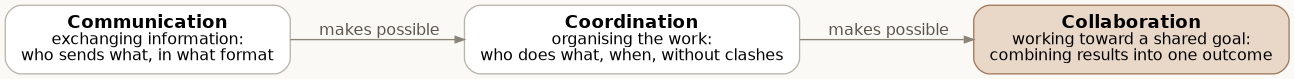

*Communication makes coordination possible, and coordination makes collaboration possible.*

**Communication** is exchanging information: what is sent, between whom, in what format. Agents need a shared language. For LLM agents that is usually a structured message (who sent it, to whom, about which task, what it says), often JSON, rather than free text, so that other agents and code can read it reliably.

**Coordination** is organising the work: deciding who does what and when, so agents do not duplicate effort, clash over resources or wait on each other unnecessarily. Two chatbots answering the same customer, or two robots heading for the same spill, are coordination failures.

**Collaboration** is working toward a shared goal: combining partial results into one outcome that none of the agents could produce alone, such as one coherent honeymoon plan from four specialists' findings.

Every design in the rest of this session is a different way of providing these three. Here is the communication layer all our demos will use: a simple message format and a log, so you can always see who said what to whom.

In [ ]:
message_log = []

def send(sender, recipient, kind, content, task_id=""):
    """Record one message between agents (or between an agent and the user)."""
    message = {"from": sender, "to": recipient, "kind": kind, "task_id": task_id, "content": content}
    message_log.append(message)
    print(f"   [{kind:9s}] {sender:>18s} -> {recipient:<18s} {content[:80]}")
    return message

send("user", "coordinator", "request", "Plan our Bali honeymoon", task_id="T1")
print("\nOne message, as data:", json.dumps(message_log[-1]))

## 3. Who decides? Three architectures

A MAS is not a pile of agents; it is a coordinated system where agents interact, cooperate and sometimes compete. Two questions shape it. **How are the agents organised?** That is the **architecture**: the structural blueprint of how control, decisions and responsibilities are distributed. **How do they interact to get work done?** That is the **design pattern**: a reusable interaction model within an architecture, such as manager/worker, swarm or federated teams.

Think of a software team on a big project. The architecture is the management model: does one project manager assign every task, do developers self-organise, or do leads oversee modules while teams collaborate across boundaries? The patterns are how collaboration happens inside that model: a senior developer assigning work to juniors, pairs reviewing each other's code, or backend, frontend and QA teams working semi-independently but aligned. Together they decide a system's **efficiency, robustness and scalability**.

There are three main architectures: **centralized** (a single controller assigns tasks and makes global decisions), **decentralized** (agents act autonomously and coordinate directly with each other) and **hybrid** (central oversight combined with agent autonomy).

### 3.1 Centralized architecture

Imagine a software team where one project manager makes every decision: priorities, task assignments, progress checks. Developers execute and rely on the manager for coordination. That is a **centralized architecture**: a **single central controller** oversees all agents. It collects each agent's local observations, processes them to make global decisions, and sends instructions back.

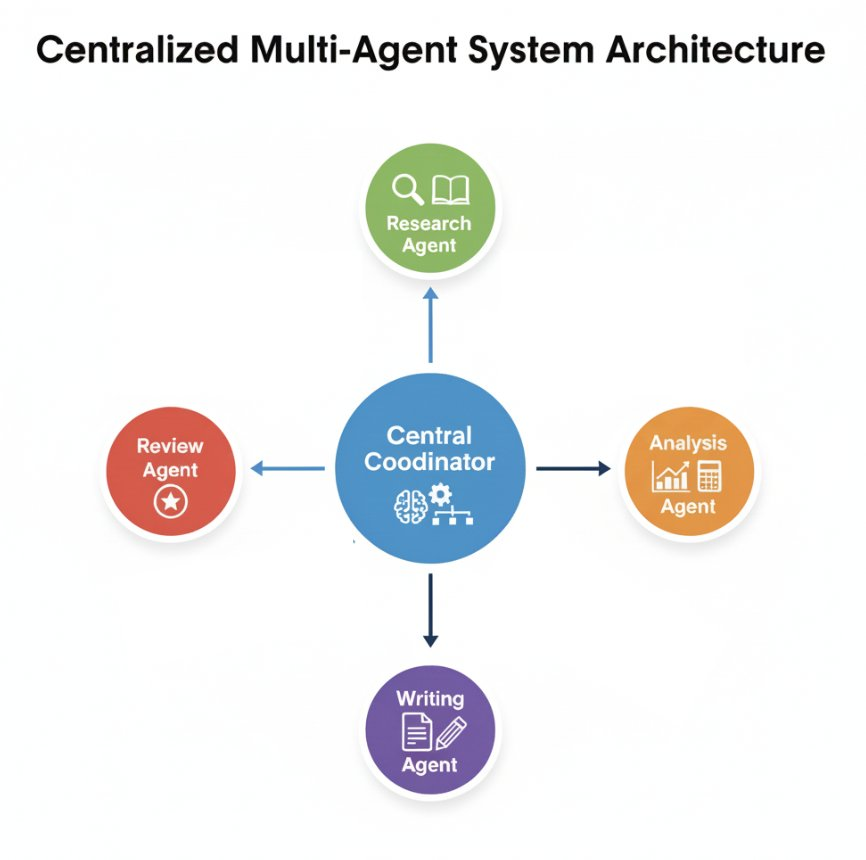

*A central coordinator directs research, analysis, writing and review agents.*

Information flows in a loop: **agents report to the controller** (each senses its local environment, such as a robot detecting obstacles or a drone its position, and sends a status update, so the controller has a complete global view); **the controller decides** (it analyses everything and chooses each agent's next action so their work is coordinated; in a warehouse, it makes sure robot A does not collide with robot B while optimising both routes); **the controller instructs, and agents execute** (then sense again). The controller has the **global view**; agents are mainly **executors with limited autonomy**. It is simple to design, but it has a **single point of failure**.

It works like an orchestra: the conductor has the full score and sees every musician, so the performance is coordinated. (A decentralized system is more like a jazz ensemble improvising together.) Its strengths:

- **Simple coordination, monitoring and debugging.** All decision logic is in one place. The controller allocates tasks so agents do not work at cross-purposes; all data flows through it, so health is easy to monitor; and when something breaks, there is one place to look.
- **A global perspective.** The controller sees all agents and resources, so it can resolve conflicts, allocate efficiently and optimise the whole.
- **Strong when priorities are critical.** It enforces one set of rules uniformly, ideal for precise, repeatable outcomes: an assembly line where a central system orchestrates robots' timing, or enterprise software where uniformity and control come first.

Here is a centralized version of DilSeTrips' support desk. A coordinator LLM routes each incoming query to one of three specialist chatbots; the specialists answer only what they are given.

In [ ]:
specialist_roles = {
    "bookings_bot": "You handle booking confirmations and changes for DilSeTrips. Reply in two sentences.",
    "refunds_bot": "You handle refunds and cancellations for DilSeTrips. Reply in two sentences.",
    "advice_bot": "You give travel advice (safety, weather, food) for DilSeTrips trips in India. Reply in two sentences.",
}
specialist_names = list(specialist_roles.keys())

incoming_queries = [
    "Where is my booking confirmation for Snow Valley Cottage?",
    "I want a refund for my cancelled Goa trip.",
    "Is it safe to drive to Manali when it's snowing?",
    "Can you suggest vegetarian restaurants in Old Manali?",
]

routing_schema = {"title": "routing", "description": "Which specialist handles each query", "type": "object",
                  "properties": {"assignments": {"type": "array", "items": {"type": "object", "properties": {
                      "query_number": {"type": "integer"}, "specialist": {"type": "string", "enum": specialist_names}},
                      "required": ["query_number", "specialist"]}}},
                  "required": ["assignments"]}

def centralized_desk(coordinator_is_up):
    start = call_count["total"]
    for number in range(len(incoming_queries)):
        send("customer", "coordinator", "query", incoming_queries[number], task_id=f"Q{number + 1}")
    if not coordinator_is_up:
        print("\n   The coordinator is down. No specialist knows which query is theirs, so every query waits.")
        return call_count["total"] - start

    numbered = ""
    for number in range(len(incoming_queries)):
        numbered = numbered + f"{number + 1}. {incoming_queries[number]}\n"
    routing = ask_structured(routing_schema, "You are the coordinator of a support desk. Assign each query to one specialist.",
                             numbered)
    print()
    for assignment in routing["assignments"]:
        query = incoming_queries[assignment["query_number"] - 1]
        send("coordinator", assignment["specialist"], "assign", query, task_id=f"Q{assignment['query_number']}")
        answer = ask(specialist_roles[assignment["specialist"]], query)
        send(assignment["specialist"], "customer", "answer", answer, task_id=f"Q{assignment['query_number']}")
    return call_count["total"] - start

demo_costs["3.1 Centralized desk"] = centralized_desk(coordinator_is_up=True)

Everything went through one coordinator, so the log is easy to follow and every query reached the right specialist. Now the weakness. We run the same desk with the coordinator down.

**Before you run it:** the three specialists are all working. How many queries get answered?

In [ ]:
# TODO: HW1 [Easy] - With the coordinator down, nothing is answered even though every specialist is healthy. Design a fallback:
# what could each specialist do on its own, and what new problem (think duplicates) does that fallback create?
calls_while_down = centralized_desk(coordinator_is_up=False)
print(f"   Model calls made while the coordinator was down: {calls_while_down}")

None. That is the **single point of failure**. A centralized LLM support system has more limitations under load:

- **Single point of failure:** if the orchestrator crashes, no chatbot can respond.
- **Scalability:** as queries grow, the orchestrator becomes a bottleneck and responses slow down.
- **Reduced autonomy:** chatbots cannot prioritise an urgent query or reroute work by themselves.
- **Communication overhead:** constant traffic between every chatbot and the orchestrator.
- **Delayed decisions:** every chatbot waits for instructions, which hurts in a sudden surge of urgent tickets.

Centralized is easy to control, but it struggles with scale, responsiveness and robustness. So what if we remove the orchestrator?

### 3.2 Decentralized architecture

Think of a big open-source project on GitHub. No project manager assigns tasks: each contributor picks features or bugs, talks directly to other contributors, and coordinates through the shared repository and discussion threads. The project thrives on peer-to-peer collaboration and collective knowledge.

In a **decentralized architecture**, **all agents operate autonomously, with no central controller**. Each decides from its local observations, its own goals and messages from nearby agents. Agents may share information directly, but nobody controls the whole. It is **robust** (one agent failing does not stop the others) and **scales** well, because decisions are distributed.

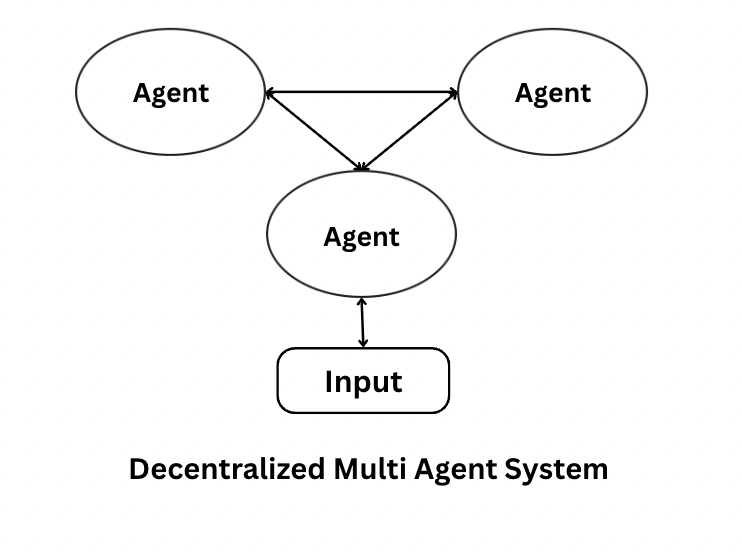

*Agents talk to each other directly; any of them can receive input.*

In a decentralized support desk, each chatbot is an independent team member running a loop: **observe** (its own new messages, and what it believes the others are doing); **decide locally** (handle it myself, or hand it to a peer); **communicate with peers** (who is free, who is taking what, so no two chatbots answer the same question); **act** (answer the customer and update its memory); **learn** (over time, which queries it handles best and which peers are reliable); and **repeat**, with no boss involved.

Here is that desk, with four chatbots A to D. Bot B is overloaded and must decide what to do. It only knows what is on the **status board**, which peers update when they get a chance, so it can be out of date. Here, it says C is free, but C was flooded with new queries a minute ago.

In [ ]:
actual_queue_length = {"bot_A": 1, "bot_B": 4, "bot_C": 3, "bot_D": 0}     # the truth
status_board = {"bot_A": 1, "bot_B": 4, "bot_C": 0, "bot_D": 0}            # what peers last posted (C's entry is stale)

delegation_schema = {"title": "delegation", "description": "A chatbot's local decision", "type": "object",
                     "properties": {"action": {"type": "string", "enum": ["handle it myself", "delegate"]},
                                    "delegate_to": {"type": "string", "enum": ["bot_A", "bot_C", "bot_D", "none"]},
                                    "reason": {"type": "string"}},
                     "required": ["action", "delegate_to", "reason"]}

new_query = "VIP customer: our flight was cancelled, please rebook us today."
start = call_count["total"]
send("customer", "bot_B", "query", new_query, task_id="Q9")

asked_already = []
handled = False
attempts = 0
while not handled and attempts < 3:              # a hard limit: agents must never loop forever
    attempts = attempts + 1
    decision = ask_structured(
        delegation_schema,
        "You are support chatbot bot_B in a team with no manager. Decide locally. Prefer delegating when you are overloaded.",
        f"New query: {new_query}\nYour queue: {actual_queue_length['bot_B']} queries.\n"
        f"Status board (posted by peers, may be out of date): {status_board}\n"
        f"Peers that already refused: {asked_already}")
    print(f"\n   bot_B decides: {decision['action']} -> {decision['delegate_to']} ({decision['reason']})")
    if decision["delegate_to"] in asked_already:
        print(f"   {decision['delegate_to']} already refused; bot_B must not ask again.")
        continue
    if decision["action"] == "handle it myself" or decision["delegate_to"] == "none":
        send("bot_B", "customer", "answer", "I'll handle this myself, though I'm busy.", task_id="Q9")
        handled = True
    else:
        peer = decision["delegate_to"]
        send("bot_B", peer, "handover", new_query, task_id="Q9")
        if actual_queue_length[peer] >= 3:                       # the peer checks its REAL queue
            send(peer, "bot_B", "refuse", f"Sorry, I actually have {actual_queue_length[peer]} queries.", task_id="Q9")
            status_board[peer] = actual_queue_length[peer]        # the board gets corrected, too late for this query
            asked_already.append(peer)
        else:
            send(peer, "bot_B", "accept", "I'll take it.", task_id="Q9")
            handled = True

if not handled:
    send("bot_B", "customer", "answer", "Sorry for the wait: I'm handling this myself now.", task_id="Q9")
demo_costs["3.2 Decentralized handover"] = call_count["total"] - start
# TODO: HW2 [Medium] - Keep the board accurate by having every bot broadcast its queue after every change. Count the messages
# per change for 4 bots, then for 20. Why does communication overhead grow faster than the number of agents?

Bot B trusted the board, handed the VIP query to C, was refused, and had to decide again before D took it. Nobody failed, and there was no single point of failure, but the stale board cost an extra round of messages and an extra model call, and the VIP waited longer. That one run shows most of the limitations of decentralized systems:

- **Communication overhead:** agents constantly exchange availability and context; with 20 chatbots, every new query can trigger several "who is free?" messages, congesting the network and slowing replies.
- **Inconsistent global knowledge:** each agent has only a local view; B thought C was free, but C was overloaded.
- **Coordination complexity:** without a manager, interdependent work is hard to coordinate; if messages are delayed, two chatbots can answer the same customer.
- **Hard to debug and monitor:** emergent behaviour is hard to trace; finding which agent caused a delay across several handovers needs logging across all of them (our `message_log`).
- **Slower learning:** each agent learns from partial experience; A may learn that C is good at refunds long before B does.

Can we keep the strengths of both designs and reduce their weaknesses?

### 3.3 Hybrid architecture

Think of a large software company. A **project manager** sets deadlines, allocates milestones and protects the overall vision. Meanwhile, **developers and team leads** work independently on their modules, make technical decisions, and coordinate directly with each other on dependencies. Central guidance aligns the big picture; local autonomy keeps work fast and flexible.

A **hybrid architecture** strategically combines centralized and decentralized elements. Its components:

- **Central oversight:** a coordinator or supervisory layer sets **global objectives and priorities**, **resolves conflicts** when tasks overlap, and **monitors** overall performance, but does **not micromanage** every agent, which avoids the bottleneck.
- **Autonomous agents:** each makes local decisions from its own perception, coordinates with peers, and executes without waiting for central instructions, with its own memory, reasoning and problem-solving.
- **Peer-to-peer coordination:** agents exchange information, share workload and collaborate directly, adapting to failures and spikes.
- **Integrated global and local knowledge:** central awareness of objectives and critical decisions, plus local intelligence for observation and execution.

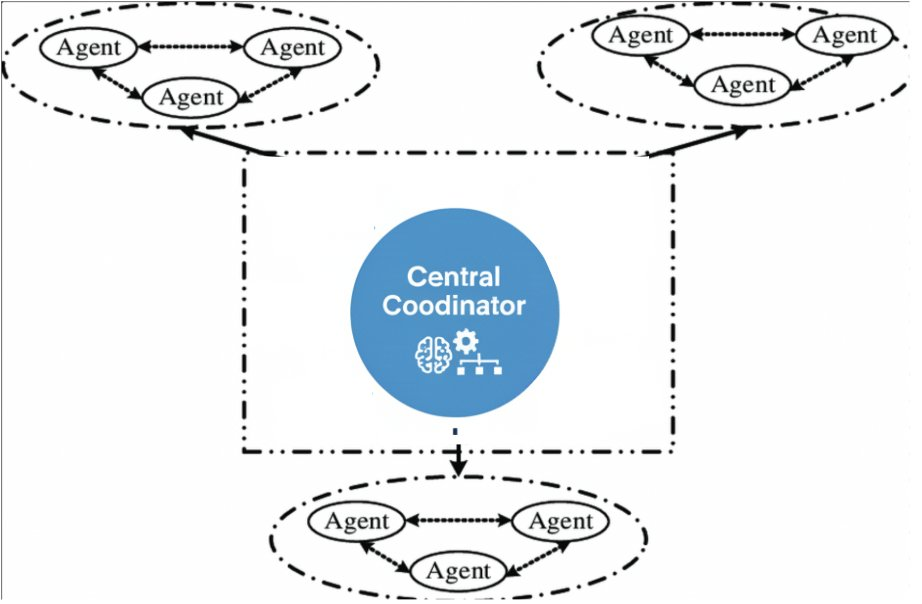

*A central coordinator oversees clusters of agents that collaborate directly within each cluster.*

Its strengths, with the e-commerce support example from the session document: a **balance of control and flexibility** (the request manager routes queries; returns and shipping agents solve their parts); **scalable and reliable** (add a tax-compliance agent for international orders by plugging it in); **robust** (if the shipping agent's API fails, the coordinator switches to another provider); **efficient collaboration** (the returns agent tells the shipping agent the parcel's weight directly, without going through the coordinator); **global and local intelligence** (the coordinator makes sure the query is fully solved; a translation agent puts the answer in German); a **better user experience** ("can I return this and what will shipping cost?" gets one structured answer, not a runaround); and it suits **complex applications** where some tasks need strict control and others freedom (in finance, the coordinator enforces compliance while agents analyse markets).

The workflow has three phases:

| Stage | Who handles it | Coordinator's role | Specialised agents' role |
|---|---|---|---|
| 1. Task intake | Coordinator | Receives the query and interprets intent | |
| 2. Task planning | Coordinator | Breaks it into sub-tasks; decides which agents are needed | |
| 3. Delegation | Coordinator | Assigns each sub-task to the right agent | |
| 4. Execution | Agents | | Do their sub-task with tools, APIs or reasoning |
| 5. Collaboration | Agents | | Share information directly with each other when needed |
| 6. Reporting | Agents | | Send results back to the coordinator |
| 7. Synthesis | Coordinator | Combines results into one answer | |
| 8. Delivery | Coordinator | Presents the final response | |

To build one: **define the coordinator** (the entry point, needing strong reasoning to understand intent and plan); **design the specialised agents** (each with a clear role, goal and tools, such as a stock analyst agent with a market-data API); **establish communication protocols** (a standard message format such as JSON, with task ID, sender and content, plus rules for agent-to-agent messages, like our `send`); and **implement a control mechanism** (a routing engine that picks agents by intent, complexity and capability).

The session document's example is a customer who wants to return a product and ship it to Germany: the request manager splits it into a returns task and a shipping task; the returns agent checks the policy and starts the return; the shipping agent checks customs documents and costs, asking the returns agent directly for the parcel's weight; the manager combines both into one answer. Here is the DilSeTrips version: a couple wants to cancel one stay and use the refund towards another. The booking database and options are **pretend data written for this exercise**.

In [ ]:
# ---- Pretend booking data for this exercise ----
goa_booking = {"stay": "Palm Grove Homestay, Goa", "dates": "14-17 Feb", "paid": 12000, "cancellation_fee_rate": 0.20}
coorg_options = [
    {"stay": "Coffee Estate Cottage, Coorg", "price": 8800, "notes": "quiet, veg kitchen"},
    {"stay": "Misty Hills Resort, Coorg", "price": 13500, "notes": "spa, mixed menu"},
]

def refund_due(booking):
    fee = booking["paid"] * booking["cancellation_fee_rate"]
    refund = booking["paid"] - fee
    print(f"   refund arithmetic: Rs {booking['paid']} - {booking['cancellation_fee_rate']:.0%} fee (Rs {fee:.0f}) = Rs {refund:.0f}")
    return refund

decompose_schema = {"title": "decomposition", "description": "Sub-tasks for specialised agents", "type": "object",
                    "properties": {"subtasks": {"type": "array", "items": {"type": "object", "properties": {
                        "agent": {"type": "string", "enum": ["cancellation_agent", "booking_agent"]}, "task": {"type": "string"}},
                        "required": ["agent", "task"]}}},
                    "required": ["subtasks"]}

user_request = "Please cancel our Goa homestay for 14-17 Feb and book something quiet in Coorg for the same dates instead, using the refund."
start = call_count["total"]
send("user", "request_manager", "request", user_request, task_id="H1")

# Phases 1-3 (central): intake, planning, delegation
plan = ask_structured(decompose_schema, "You are the request manager. Split the request into sub-tasks for your agents.", user_request)
for subtask in plan["subtasks"]:
    send("request_manager", subtask["agent"], "assign", subtask["task"], task_id="H1")

# Phase 4 (decentralized): the cancellation agent works on its own
refund = refund_due(goa_booking)
cancellation_report = ask("You are the cancellation agent. Confirm the cancellation in one sentence, stating the refund.",
                          f"Booking: {goa_booking}. Refund due: Rs {refund:.0f}.")

# Phase 5 (decentralized): the booking agent asks the cancellation agent DIRECTLY, not via the manager
send("booking_agent", "cancellation_agent", "question", "How much refund credit can I use for the new booking?", task_id="H1")
send("cancellation_agent", "booking_agent", "answer", f"Rs {refund:.0f} of credit.", task_id="H1")
booking_report = ask("You are the booking agent. Pick the best Coorg option for a quiet couple within or near the credit, "
                     "and state any amount still to pay. Two sentences.",
                     f"Credit: Rs {refund:.0f}. Options: {coorg_options}")

# Phase 6 (decentralized): report back
send("cancellation_agent", "request_manager", "report", cancellation_report, task_id="H1")
send("booking_agent", "request_manager", "report", booking_report, task_id="H1")

# Phases 7-8 (central): synthesis and delivery
final_answer = ask("You are the request manager. Combine your agents' reports into one short, friendly answer for the couple.",
                   f"Request: {user_request}\nCancellation: {cancellation_report}\nBooking: {booking_report}")
send("request_manager", "user", "answer", final_answer, task_id="H1")
print("\nFINAL ANSWER:\n" + final_answer)
demo_costs["3.3 Hybrid rebooking"] = call_count["total"] - start

Read the message log from top to bottom and you can see all eight stages. Notice the one message that did **not** go through the manager: the booking agent asking the cancellation agent for the refund amount. That direct exchange is the decentralized part of a hybrid; without it, the manager would have to relay every detail between agents. And notice the refund itself was computed by code, not by an LLM: Rs 12,000 minus a 20% fee is Rs 9,600, every time.

### The three architectures side by side

| Aspect | Centralized | Decentralized | Hybrid |
|---|---|---|---|
| Control | One controller manages all agents | No central control; agents act autonomously | Central oversight plus agent autonomy |
| Decision-making | Controller decides and assigns | Each agent decides for itself | Coordinator plans globally; agents execute locally |
| Scalability | Limited: the controller is a bottleneck | High | Moderate to high |
| Reliability | Low: a single point of failure | High: no central node to fail | Higher: agents plus a central fallback |
| Speed of response | Slower: depends on the controller | Faster: local decisions | Balanced |
| Communication | Everything flows through the controller | Peer to peer | Both: direct between agents, aggregated centrally |
| Best for | Small teams, simple workflows, strong oversight (a hub routing all LLM queries) | Large, dynamic, distributed systems (swarm robotics, blockchain, decentralized LLM agents) | Domains needing global strategy and local autonomy (LLM customer support, smart healthcare) |

## 4. Who talks to whom? Four design patterns

Back to the software company. It has several teams with different roles (backend, frontend, QA, DevOps). Sometimes a project manager coordinates them; sometimes teams collaborate directly; depending on the work, they run as a **pipeline**, collaborate **peer to peer**, or specialise by **domain**. **MAS design patterns** are the proven blueprints for exactly this: how agents are organised, interact and collaborate. They turn an architecture into a working system by defining **roles, relationships and workflows**.

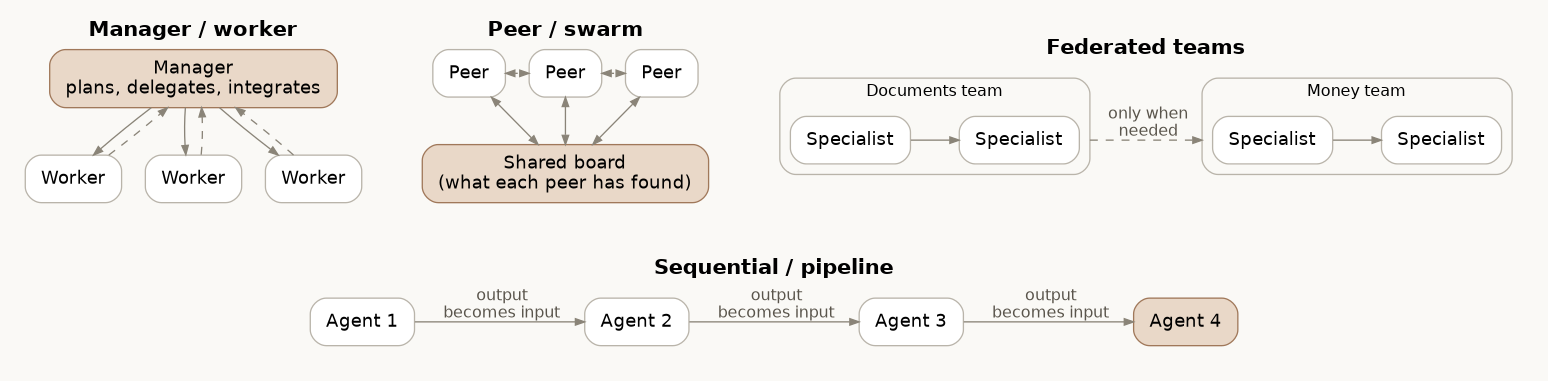

*Manager/worker, peer/swarm, federated teams, and sequential pipeline.*

- **Manager/worker:** centralized task assignment to specialised workers.
- **Peer/swarm:** fully decentralized collaboration among equals.
- **Federated teams (specialist agents):** groups with distinct expertise, coordinating centrally or in clusters.
- **Sequential pipeline:** ordered execution, each agent's output becoming the next agent's input.

### 4.1 Manager / worker

A project manager receives a client's request for a new feature, breaks it into frontend, backend and QA tasks, gives each to a specialised team, and integrates the results into the delivered product. In the **manager/worker pattern**, a **central manager agent** coordinates the work, assigns tasks to specialised **worker agents** and collects their results; workers are semi-autonomous and focus on their task. It suits **centralized or hybrid** architectures wherever work must be divided and orchestrated.

**Advantages:** **clear delegation** (the manager decides who does what, so nothing is duplicated); **efficient use of specialists** (each worker focuses on its expertise); **central oversight** (the manager sees every task, so it can monitor, prioritise and reassign overloaded workers); and it **simplifies complex workflows** where sequencing and supervision matter, such as a drafting agent finishing before a QA agent reviews. **Limitations:** a **single point of failure** (if the manager fails, the workflow stalls); a **scalability bottleneck** as workers multiply; **reduced worker autonomy** (the shipping agent cannot proactively suggest better delivery options without approval); and **communication overhead** from constant reporting.

Here is DilSeTrips' honeymoon request handled this way: the manager plans, three workers answer, the manager integrates. One more thing is worth checking, because it exposes a subtle weakness of this pattern: **if the manager's plan forgets part of the request, no worker will cover it.** So before delegating, our code checks that every requirement in the request appears in some task.

In [ ]:
worker_roles = {
    "visa_worker": "You are a visa and documents specialist for Indian travellers. Under 100 words. Say what to verify officially.",
    "budget_worker": "You are a travel budget and insurance specialist. Under 100 words. Give a rough budget in rupees and an insurance view.",
    "itinerary_worker": "You are an itinerary specialist for vegetarian travellers. Under 120 words. A day-by-day outline.",
}
worker_names = list(worker_roles.keys())

manager_plan_schema = {"title": "manager_plan", "description": "Tasks for worker agents", "type": "object",
                       "properties": {"tasks": {"type": "array", "items": {"type": "object", "properties": {
                           "worker": {"type": "string", "enum": worker_names}, "task": {"type": "string"}},
                           "required": ["worker", "task"]}}},
                       "required": ["tasks"]}

start = call_count["total"]
send("user", "manager", "request", honeymoon_request, task_id="M1")
manager_plan = ask_structured(manager_plan_schema, "You are the manager of a travel planning team. Give each worker one clear task.",
                              honeymoon_request)

# Coverage check: does every requirement in the request appear in some task?
# TODO: HW3 [Medium] - This check uses fixed keywords. Make the manager itself return, for each requirement it found in the
# request, which worker covers it, and have code reject a plan that leaves any requirement uncovered.
requirements = ["visa", "insurance", "budget", "itinerary"]
all_task_text = ""
for task in manager_plan["tasks"]:
    all_task_text = all_task_text + task["task"].lower() + " "
for requirement in requirements:
    if requirement not in all_task_text:
        print(f"   WARNING: no task mentions '{requirement}'. With manager/worker, nobody will cover it.")

worker_results = {}
for task in manager_plan["tasks"]:
    send("manager", task["worker"], "assign", task["task"], task_id="M1")
    result = ask(worker_roles[task["worker"]], task["task"] + "\nContext: " + honeymoon_request)
    worker_results[task["worker"]] = result
    send(task["worker"], "manager", "report", result, task_id="M1")

results_text = ""
for worker in worker_results:
    results_text = results_text + f"[{worker}]\n{worker_results[worker]}\n\n"
integrated = ask("You are the manager. Integrate your workers' reports into one plan under 300 words, with a short "
                 "'check before you book' list at the end.", f"Request: {honeymoon_request}\n\n{results_text}")
print("\nINTEGRATED PLAN:\n" + integrated)
demo_costs["4.1 Manager / worker"] = call_count["total"] - start

Compare this with the generalist's answer in Chapter 1: each section now has depth, because each worker spent its whole answer on one domain. And look at the cost line at the end of the notebook: this pattern used several model calls where the generalist used one.

Did the coverage check print a warning? Managers sometimes fold insurance into the budget task, or forget it. In a manager/worker system, the manager's plan is the only map; a requirement that is not on it simply does not get done.

### 4.2 Peer / swarm

In an open-source project, no single manager directs every action. Developers talk directly, share knowledge, and decide collectively; the product emerges from their combined work. In the **peer/swarm pattern**, **all agents are equals** with no coordinator. Each **peer** makes its own decisions; **swarm behaviour** emerges when many peers follow simple local rules that together produce complex collective outcomes.

The session document's LLM example is a research institute analysing thousands of papers: each agent analyses a subset independently, shares findings with neighbouring agents to avoid duplication, and the collective produces a coherent literature summary with no coordinator. It works well because it **scales horizontally** (more agents, faster processing), is **robust** (if some fail, others continue) and **adapts quickly** as new papers arrive.

**Advantages:** **robustness and fault tolerance** (if some search-and-rescue drones run out of battery, the rest keep searching); **scalability** (hundreds of agents with no central node to overwhelm); **high autonomy** (an autonomous car changes lanes from what it sees, without waiting for approval); **emergent intelligence** (delivery drones that only avoid collisions and head to their packages organise themselves efficiently). **Limitations:** **no global oversight** (one agent dwells on minor details while another skips key sections, and the result is uneven); **coordination complexity** (emergent behaviour can be unpredictable, like drones clustering in one area); **communication overhead** (every peer updating its neighbours); and **slower convergence** when the task needs agreement, such as settling the final wording of a report.

Here is a small swarm. Three peers summarise the real Wikivoyage guide to Manali, with no coordinator. They share a **board** (an example of the environment being used for communication): each peer follows two local rules. **Claim the first unclaimed section on the board and post two new insights, skipping anything already posted.** And **if nothing is left to claim, write the summary from the board.**

In [ ]:
def fetch_guide_sections(place):
    """Download a Wikivoyage page and split it into {heading: text}."""
    response = requests.get("https://en.wikivoyage.org/w/api.php",
                            params={"action": "query", "prop": "extracts", "explaintext": 1, "redirects": 1, "titles": place, "format": "json"},
                            headers={"User-Agent": "GenAI-course-agents-notebook/1.0 (educational use)"}, timeout=30)
    pages = response.json()["query"]["pages"]
    text = ""
    for page_id in pages:
        if "extract" in pages[page_id]:
            text = pages[page_id]["extract"]
    sections = {}
    current = "Introduction"
    sections[current] = ""
    for line in text.split("\n"):
        if line.startswith("== ") and line.endswith(" =="):
            current = line[3:-3].strip()
            sections[current] = ""
        else:
            sections[current] = sections[current] + line + "\n"
    return sections

guide = fetch_guide_sections("Manali")
board = {"unclaimed": [], "insights": []}
for heading in ["See", "Do", "Eat", "Get around"]:
    if heading in guide and guide[heading].strip() != "":
        board["unclaimed"].append(heading)
print("Sections on the board to claim:", board["unclaimed"])

peers = ["peer_1", "peer_2", "peer_3"]
start = call_count["total"]
summary_written = False
turn = 0
while not summary_written and turn < 10:            # a hard limit on turns
    peer = peers[turn % len(peers)]
    turn = turn + 1
    if len(board["unclaimed"]) > 0:
        # Rule 1: claim the first unclaimed section, post two NEW insights
        section = board["unclaimed"].pop(0)
        already = "\n".join(board["insights"])
        insights = ask(f"You are {peer}, one of several equal peers. Read one section of a travel guide and post exactly two short, "
                       "useful insights for a quiet vegetarian couple, one per line. Do not repeat anything already on the board.",
                       f"Section '{section}':\n{guide[section][:2500]}\n\nAlready on the board:\n{already}")
        for line in insights.split("\n"):
            if line.strip() != "":
                board["insights"].append(f"({section}) {line.strip().lstrip('-* ')}")
        send(peer, "board", "post", f"claimed '{section}', posted insights", task_id="S1")
    else:
        # Rule 2: nothing left to claim, so this peer writes the summary from the board
        summary = ask(f"You are {peer}. Using only the insights on the board, write a 4-sentence Manali briefing for a quiet vegetarian couple.",
                      "\n".join(board["insights"]))
        send(peer, "user", "answer", summary, task_id="S1")
        print("\nSWARM SUMMARY (no coordinator):\n" + summary)
        summary_written = True

print("\nBoard:")
for insight in board["insights"]:
    print("  ", insight)
demo_costs["4.2 Peer / swarm"] = call_count["total"] - start
# TODO: HW4 [Hard] - No peer decides which sections matter most, so "Get around" gets the same attention as "Eat". Add a local rule
# (not a coordinator) that makes the swarm cover what matters to this couple first. What happens if two peers claim at once?

No agent was in charge, yet the work was divided, duplicates were avoided, and a summary appeared: **emergent** coordination from two local rules and a shared board. Notice too what the swarm could not do: nobody judged that "Eat" matters more than "Get around" for this couple, so every section got equal effort. That is the "no global oversight" limitation in miniature. (Here the peers take turns because our loop runs them one at a time; in a real swarm they run concurrently, and two peers claiming the same section at once becomes a real coordination problem.)

### 4.3 Federated teams / specialist agents

A large consulting firm has specialised teams: tax, legal, IT and strategy. On a complex client project, each team works within its expertise and collaborates with other teams only when needed; the outcome emerges from their coordinated efforts. In the **federated teams pattern**, agents are **grouped by expertise**; each **specialist** or team works autonomously in its domain; **collaboration happens across teams** when a task needs several skills. Unlike a swarm, agents are **not all equals** (they have specialised roles); unlike manager/worker, there may be **no single central manager**.

**Advantages:** **domain expertise** (each focuses on its strength); **parallel processing** (teams work at the same time); **flexible collaboration** (only when needed, so fewer dependencies); **scalable across domains** (add a team without disturbing the others). **Limitations:** **integration complexity** (combining outputs from different teams is hard); **coordination overhead** (inter-team communication needs clear protocols); **dependence on each team** (one weak team weakens the result); and **not fully decentralized** (it needs some standardisation to work smoothly).

That last point is the key to making federated teams work: **a shared report format**. Below, a documents team and a money team each return the same structure. The money team needs one fact from the documents team (the visa fee), and asks for it across the team boundary. Because both reports share a format, plain code can integrate them, including adding up the costs.

In [ ]:
team_report_schema = {
    "title": "team_report", "description": "A standard report every team returns", "type": "object",
    "properties": {
        "team": {"type": "string"},
        "findings": {"type": "array", "items": {"type": "string"}},
        "costs": {"type": "array", "items": {"type": "object", "properties": {
            "item": {"type": "string"}, "amount_inr": {"type": "integer", "description": "For both people, in rupees"}},
            "required": ["item", "amount_inr"]}},
        "open_questions": {"type": "array", "items": {"type": "string"}},
    },
    "required": ["team", "findings", "costs", "open_questions"],
}

start = call_count["total"]
documents_report = ask_structured(team_report_schema,
    "You are the documents team (visa and passport specialists). Report in the standard format. Estimate costs for two people "
    "and list anything the couple must verify officially as open questions.",
    honeymoon_request)
send("documents_team", "board", "report", f"{len(documents_report['findings'])} findings, {len(documents_report['costs'])} cost items", task_id="F1")

# Cross-team collaboration, only for what is needed: the money team asks for the document costs
document_costs_text = json.dumps(documents_report["costs"])
send("money_team", "documents_team", "question", "What document costs should the budget include?", task_id="F1")
send("documents_team", "money_team", "answer", document_costs_text, task_id="F1")

money_report = ask_structured(team_report_schema,
    "You are the money team (budget and insurance specialists). Report in the standard format. Include flights, stay, food and "
    "insurance for two people as cost items. Do not repeat the document costs you were given; they are counted separately.",
    honeymoon_request + "\nDocument costs from the documents team: " + document_costs_text)

# Integration is plain code, because both teams used the same format
# TODO: HW6 [Easy] - Add a third team (food and itinerary) that returns the same team_report_schema. How many lines of the
# integration code below need to change? What does that tell you about standard formats in federated systems?
total = 0
print("\nCOST ITEMS (both people):")
for report in [documents_report, money_report]:
    for cost in report["costs"]:
        total = total + cost["amount_inr"]
        print(f"   {report['team']:18s} {cost['item']:35s} Rs {cost['amount_inr']:>8,}")
print(f"   {'':18s} {'TOTAL':35s} Rs {total:>8,}")
budget = 200000
print(f"   Budget Rs {budget:,} (Rs 2 lakh); left over: Rs {budget - total:,}")
print("\nOPEN QUESTIONS:")
for report in [documents_report, money_report]:
    for question in report["open_questions"]:
        print(f"   [{report['team']}] {question}")
demo_costs["4.3 Federated teams"] = call_count["total"] - start

The total is computed by code, from numbers each team was required to give in the same shape, so you can see at once whether the plan fits the Rs 2 lakh budget. The estimates themselves come from the model's general knowledge, not live prices; treat them as a rough first pass. Notice also that the open questions from both teams are listed together, which is often the most useful part of a federated report: what still needs a human to check.

Integration is where federated systems usually struggle. Here it was easy only because we forced a shared format. Without it, someone (or another LLM call) would have to translate between teams' different styles.

### 4.4 Sequential / pipeline orchestration

A CI/CD pipeline runs code through fixed stages: linting, unit tests, integration tests, deployment. Each stage depends on the previous one's output; if a stage fails, the pipeline stops or triggers a fix. In the **pipeline pattern**, agents are organised in a **defined sequence**; each does one sub-task and passes its result on. You built one in Session 1: the travel planner's researcher, planner, optimizer and QA.

**Advantages:** **ordered execution**; **clear dependencies** (each agent knows its input and its role); **modular design** (swap or improve one agent independently); **predictable outcomes** (little emergent surprise). **Limitations:** a **single point of delay** (one slow agent delays everything); **less flexible** (no parallelism, poor for very dynamic tasks); **error propagation** (a mistake early on flows into every later stage); and it **needs strict orchestration**.

Error propagation is the one that hurts most in LLM pipelines, so let us watch it happen. The research stage's output below is **pretend tool data with a deliberate error**: a flight price far too low to be real. Three agents follow.

In [ ]:
research_notes = ("RESEARCH NOTES (pretend tool output):\n"
                  "- Return flights Mumbai-Bali: Rs 4,000 per person.\n"     # the deliberate error: far too cheap
                  "- Visa on arrival for Indian passport holders; verify the current fee officially.\n"
                  "- Ubud has many vegetarian cafes; Seminyak is busier and louder.")

pipeline_stages = [
    ("planner", "You are the trip planner. Using the research notes, outline a 6-day Bali honeymoon in under 80 words."),
    ("budgeter", "You are the budgeter. Using the plan and notes, estimate the total cost for two in rupees, showing the flight line, "
                 "and say how much of the Rs 2 lakh budget is left. Under 80 words."),
    ("writer", "You are the writer. Turn the budget and plan into a short, exciting message to the couple. Under 80 words."),
]

def run_pipeline(first_input, stages, checker=None):
    current = first_input
    if checker is not None:
        verdict = checker(current)
        if verdict != "ok":
            send("checker", "pipeline", "halt", verdict, task_id="P1")
            return None
    for name, role in stages:
        current = ask(role, current)
        send(name, "next stage", "output", current, task_id="P1")
    return current

start = call_count["total"]
final_message = run_pipeline(research_notes, pipeline_stages)
print("\nWHAT THE COUPLE RECEIVES:\n" + final_message)
demo_costs["4.4 Pipeline (no checker)"] = call_count["total"] - start

The flight price was wrong at stage 1. The planner built on it, the budgeter added it up faithfully, probably found a large amount left over, and the writer cheerfully told the couple they could afford upgrades. Every agent did its own job correctly; the system still produced a wrong answer, because nothing questioned the input. That is **error propagation**.

The fix is a **checker stage** placed where errors enter: a cheap agent that sanity-checks the research before anything is built on it, and stops the pipeline if something looks implausible.

In [ ]:
check_schema = {"title": "check", "description": "A sanity check", "type": "object",
                "properties": {"plausible": {"type": "boolean"}, "problem": {"type": "string"}},
                "required": ["plausible", "problem"]}

def research_checker(notes):
    result = ask_structured(check_schema,
                            "You are a fact checker. Flag any price or fact that is clearly implausible. Do not invent corrections.",
                            notes)
    if result["plausible"]:
        return "ok"
    return "Stopped before planning: " + result["problem"]

# TODO: HW5 [Medium] - A checker after every stage would catch more, but doubles the calls. Where else in this pipeline would a
# checker earn its cost? What should happen after a halt: ask a human, re-run research, or continue with a warning?
start = call_count["total"]
result = run_pipeline(research_notes, pipeline_stages, checker=research_checker)
print("\nPipeline output:", result)
demo_costs["4.4 Pipeline (with checker)"] = call_count["total"] - start

The checker flags the Rs 4,000 return flight to Bali as implausible and halts the pipeline after one cheap call, before three more calls are spent building on a wrong number. (A checker is itself an LLM and can miss things or raise false alarms; it reduces error propagation, it does not eliminate it.)

### The four patterns compared

| Pattern | Who talks to whom | Fits which architecture | Strengths | Limitations | LLM example |
|---|---|---|---|---|---|
| Manager / worker | Manager ↔ each worker | Centralized, hybrid | Clear delegation, oversight, specialists used well | Single point of failure; manager bottleneck; uncovered requirements | A coordinator routing returns and shipping queries |
| Peer / swarm | Peers ↔ peers (or via a shared board) | Decentralized | Robust, scalable, autonomous, emergent | No global oversight; unpredictable; slower agreement | Agents summarising sections of many papers |
| Federated teams | Within teams freely; across teams when needed | Hybrid, decentralized | Deep expertise, parallel, easy to add teams | Integration; needs shared formats and protocols | Documents and money teams with a shared report |
| Sequential pipeline | Each stage → the next | Centralized (the order is fixed) | Ordered, modular, predictable | Delays and errors propagate; no parallelism | Research → plan → budget → write |

## 5. What a team costs

Every demo recorded how many model calls it used. Here they are.

In [ ]:
print(f"{'Design':32s} {'Model calls':>11s}")
for design in demo_costs:
    print(f"{design:32s} {demo_costs[design]:>11d}")
print(f"\nTotal calls in this notebook: {call_count['total']}")
print(f"Messages exchanged between agents (and users): {len(message_log)}")

Read this table next to the quality of each answer. The generalist needed one call; manager/worker needed several for the same request; the pipeline without a checker spent three calls building on a wrong number, while the checker stopped it after one. On the free tier, every call is also about 15 seconds of waiting. Multi-agent systems buy **specialisation, parallelism and robustness**, and they pay in **calls, latency and coordination**. Whether the trade is worth it is a design decision, made per feature, not once for the whole product.

### Multi-agent systems in the real world

| Domain | The agents | Why a MAS | Architecture usually used |
|---|---|---|---|
| Smart power grids | Generators, solar farms, wind turbines, household meters | Highly distributed; no control room sees everything in real time | Decentralized, with regional coordinators (hybrid) |
| City-wide traffic | Traffic lights, sensors, connected cars, navigation apps | Dynamic: accidents, roadworks and crowds change by the minute | Decentralized or hybrid |
| Supply chains | Port monitors, routing agents, weather forecasters, a coordinator | Complexity and scale beyond any single agent | Hybrid |
| Specialised LLM agents | Coordinator plus healthcare, finance, travel, legal specialists | Each domain needs its own knowledge, tools and data | Centralized (manager/worker) or hybrid |
| Swarm robotics and drones | Many simple robots | Robustness and scale; local rules suffice | Decentralized (swarm) |

### Emergent behaviour: the challenge underneath

The most distinctive feature of a MAS is also its biggest risk: **emergent behaviour**, system-level behaviour that no single agent was programmed to produce, arising from their interactions. Sometimes it is the point (the swarm divided the guide among itself without a coordinator). Sometimes it is a problem: two chatbots answering the same customer, drones clustering in one area, agents politely handing a VIP query around while the customer waits. Because no one agent "contains" the behaviour, it is hard to predict, debug and control. That is why multi-agent systems need careful design, logging of every message (our `message_log`), hard limits on loops, and testing by simulation before they meet real users.

## 6. Conclusions

**Multi-agent systems are necessary when problems are too complex, distributed or dynamic for one agent.** DilSeTrips' honeymoon request spanned four domains, and a single generalist covered each one thinly.

**A MAS is built from autonomous agents in a shared environment,** each with perception, actions, reasoning and learning, and its success depends on the **three C's**: **communication** (a shared message format), **coordination** (who does what, when, without clashes) and **collaboration** (combining results into one outcome).

**Architecture decides who decides.** **Centralized** systems are easy to control and debug but have a single point of failure. **Decentralized** systems are robust and scalable but suffer from overhead and inconsistent knowledge. **Hybrid** systems combine central oversight with local autonomy, and are where most LLM applications land.

**Design patterns decide who talks to whom:** manager/worker, peer/swarm, federated teams and pipelines, each with its own strengths and failure modes.

**Specialists beat a generalist on complex tasks,** through division of labour and focused knowledge, at the cost of more calls, more latency and more coordination.

**Emergent behaviour is the central challenge:** the system does things no single agent was told to do, for better and for worse, so it needs logging, limits and testing.

### What a team does not fix

Every specialist in this notebook was the same Gemini model with a different role. Splitting the work improved **focus**; it did not make any answer **true**. Visa rules, prices and insurance advice all came from the model's general knowledge and need checking against official sources. A team of agents can be confidently wrong together, as the pipeline showed. Checkers, shared formats, code for arithmetic and humans for final decisions are what make a team trustworthy.

**Next session:** you will build these designs properly, with LangChain and with **CrewAI**, a framework designed for teams of role-based agents.

## 7. Homework

Items marked in the code have a `# TODO: HWn` comment at the exact line.

| # | Level | Task | Where |
|---|---|---|---|
| HW1 | Easy | A fallback for the centralized desk | 3.1 |
| HW2 | Medium | The cost of keeping everyone informed | 3.2 |
| HW3 | Medium | A manager that cannot forget a requirement | 4.1 |
| HW4 | Hard | A swarm with priorities, without a boss | 4.2 |
| HW5 | Medium | Where should checkers go? | 4.4 |
| HW6 | Easy | Add a third federated team | 4.3 |
| HW7 | Medium | Choose an architecture and pattern | below |

**HW2 [Medium]: the cost of keeping everyone informed.** If every bot broadcasts its queue to every other bot after each change, how many messages does one change cause with 4 bots? With 20? With 100? Write the formula, print the numbers, and explain why decentralized systems often use a shared board (like the swarm's) or a hybrid coordinator instead.

**HW7 [Medium]: choose a design (no code).** For each scenario, choose an architecture (centralized, decentralized, hybrid) and a pattern, and justify your choice in three sentences, naming one risk:

1. DilSeTrips during the Goa Carnival, when support queries jump tenfold for three days.
2. A legal-document review service where every answer must be approved by a lawyer before it is sent.
3. Monitoring 5,000 homestays' live availability across India.
4. A research assistant that must read 300 travel blogs about Ladakh and produce one guide.

**Suggested order.** HW1 and HW6 first (small changes). HW7 next, since it tests the concepts without code. Then HW3 and HW5, which make the existing patterns safer. HW2 and HW4 are about decentralized behaviour at scale; do them last.

## 8. Quick reference

| Idea | One line | In this notebook |
|---|---|---|
| Multi-agent system | Several autonomous agents interacting to reach individual or shared goals | Chapter 1 |
| Why a MAS | Complexity and scale, distribution, dynamics | 1 |
| When not | Small, centralised, stable problems | 1 |
| Building blocks | Agents, environment, perception, action, reasoning, learning | 2 |
| Three C's | Communication, coordination, collaboration | `send`, `message_log` |
| Centralized | One controller decides; single point of failure | `centralized_desk` |
| Decentralized | Agents decide locally; overhead, stale knowledge | the delegation loop |
| Hybrid | Central plan, local execution, direct peer messages | the rebooking demo |
| Manager / worker | Manager delegates and integrates | 4.1, with a coverage check |
| Peer / swarm | Equals following local rules; emergent results | 4.2, the shared board |
| Federated teams | Specialist teams with a shared format | 4.3, `team_report_schema` |
| Pipeline | Each stage feeds the next; errors propagate | 4.4, `run_pipeline`, a checker |
| Emergent behaviour | System behaviour no single agent was programmed with | Chapter 5 |
| Cost | More agents, more calls, more waiting | the cost table |